In [ ]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from deep_isochron.analysis.ode import find_limit_cycle
from deep_isochron.data import (
    resolve_device,
)
from deep_isochron.plotting import configure_rcparams
from deep_isochron.systems import FitzhughNagumo


jax.config.update("jax_enable_x64", True)
device = resolve_device(
    1
)  # the card the scheduler assigned; refuses to guess on a shared node
jax.config.update("jax_default_device", device)
configure_rcparams()

# Find the limit cycle of the system

In [2]:
ode = FitzhughNagumo()

In [3]:
cycle = find_limit_cycle(ode, jnp.asarray([3.0, 3.0]), t_settle=10.0, m=10)

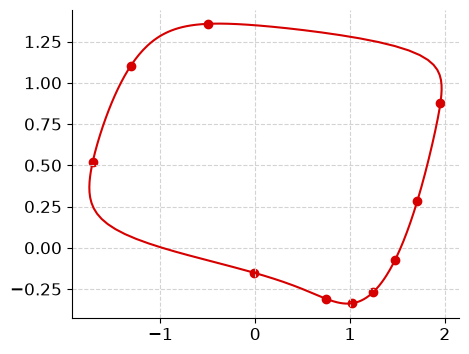

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.plot(*cycle.points.T)
ax.scatter(*cycle.x0s.T)

## Compute the flow Jacobian for each shooting segment

In [ ]:
import diffrax as dfx
from deep_isochron.analysis.ode.shooting import SHOOTING_SOLVER_CONFIG


m = len(cycle.x0s)
T = cycle.period


def flow_jacobians(u0):
    return jax.jacfwd(
        lambda x: ode.flow_to(
            T / m, x, config=SHOOTING_SOLVER_CONFIG.with_adjoint(dfx.ForwardMode())
        )
    )(u0)


jacobians = jax.vmap(flow_jacobians)(cycle.x0s)

In [ ]:
jacobians = jax.vmap(flow_jacobians)(cycle.x0s)

## Compute the monodromy matrix as a chained matmul, then compute the eigenvalues

In [ ]:
M_naive = jnp.linalg.multi_dot(jacobians[::-1])
jnp.linalg.eig(M_naive)

EigResult(eigenvalues=Array([1.69064762e-12+0.j, 1.00000000e+00+0.j], dtype=complex128), eigenvectors=Array([[-0.99770326+0.j, -0.35760233+0.j],
       [-0.06773628+0.j, -0.93387396+0.j]], dtype=complex128))

## Floquet multipliers via periodic Schur

In [54]:
# Create Q1 from the flow direction and its orthogonal complement
q1 = ode.rhs(0.0, cycle.x0s[0])
q1 = q1 / jnp.linalg.norm(q1)
q1_ortho = jnp.asarray([-q1[1], q1[0]])
Q1 = jnp.stack((q1, q1_ortho), axis=1)

In [64]:
from jaxtyping import Array, Float


def conjT(A):
    return A.conj().T


def qr(A: Float[Array, "D D"]):
    """QR decomposition of a square matrix A, with the convention that the diagonal
    elements of R are set to be positive."""

    Q, R = jnp.linalg.qr(A)
    s = jnp.expand_dims(jnp.sign(jnp.diag(R)), 0)
    return Q * s, R * s

In [65]:
def _carry_fn(Q, J):
    Q_next, A = qr(J @ Q)
    return Q_next, A


_, As = jax.lax.scan(_carry_fn, init=Q1, xs=jacobians)
jnp.exp(jax.lax.reduce_sum(jnp.log(jnp.diagonal(As, axis1=-2, axis2=-1)), axes=(0,)))

Array([1.00000000e+00, 1.69059036e-12], dtype=float64)

## Nontrivial Floquet multiplier from the Poincare map

In [ ]:
from deep_isochron.analysis.ode import PoincareMap


map = PoincareMap(ode, cycle.section, SHOOTING_SOLVER_CONFIG, 2 * cycle.period)
map(cycle.x0s[0])

(Array([-1.71442508,  0.51975079], dtype=float64),
 Array(11.22788676, dtype=float64))

In [75]:
jac = jax.jacfwd(map)(cycle.x0s[0])[0]

In [ ]:
# Works for the planar case
jnp.trace(jac)

Array(3.53808226e-09, dtype=float64)

In [ ]:
# Do we need a basis method on the CrossSection class?
n = cycle.section.normal
t = jnp.asarray((-n[1], n[0]))
t @ jac @ t

Array(3.53808206e-09, dtype=float64)